## Set Seed

In [371]:
SEED: int = 42

## Load Dataset, Preprocess & Split

- Load dataset
- Preprocess text: concatenate the messages in each thread into a single document
- Split dataset into training (80%) and test (20%) sets using the fixed seed

In [372]:
from common.read_dataset.mm_dataset import read_mm_dataset


dataset = read_mm_dataset("../data/many-models-bap/res.json")
dataset = dataset.drop(columns=["patient_temperature", "evaluation_results"])

# Concatenate messages in a thread into a single document
dataset["text"] = dataset["conversation"].apply(
    lambda conv: "\n".join([msg["content"] for msg in conv])
)

NUMBER_OF_MODELS = len(dataset["model"].unique())

dataset = dataset.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

# Sample train and test sets
train_df = dataset.sample(frac=0.8, random_state=SEED)
test_df = dataset.drop(train_df.index)

print(f"Total size: {len(dataset)}")
print(f"Train size: {len(train_df)}")
print(f"Test size: {len(test_df)}")
print(f"Number of unique models: {NUMBER_OF_MODELS}")
train_df.head()

Total size: 1000
Train size: 800
Test size: 200
Number of unique models: 4


,conversation,simulation_id,model,counselor_temperature,text
521,"[{'role': 'assistant', 'name': 'Patient', 'con...",llama3.2-vision-90b_20241121094805_t0.7_n17,llama3.2-vision:90b,0.7,"Ciao\nMi chiamo Demetra, sono un consulente in..."
737,"[{'role': 'assistant', 'name': 'Patient', 'con...",qwen2.5-32b_20241120144152_t0.5_n31,qwen2.5:32b,0.5,"Ciao\nCiao, mi chiamo Demetra e sono un chatbo..."
740,"[{'role': 'assistant', 'name': 'Patient', 'con...",aya-expanse-32b_20241121094815_t0.1_n35,aya-expanse:32b,0.1,"Ciao\nCiao, sono Demetra, un chatbot esperto i..."
660,"[{'role': 'assistant', 'name': 'Patient', 'con...",qwen2.5-32b_20241120144152_t0.7_n3,qwen2.5:32b,0.7,"Ciao\nCiao, sono Demetra, tua consulente per l..."
411,"[{'role': 'assistant', 'name': 'Patient', 'con...",aya-expanse-32b_20241121094815_t0.7_n22,aya-expanse:32b,0.7,"Ciao\nCiao, sono Demetra, un chatbot esperto i..."


## Setup the TF-IDF Vectorizer with a pre-processing pipeline

**Fixed hyperparameters:**
- maximum vocabulary size: 15,000 terms
- lowercase: True
- preprocessor: remove digits from text
- keep stop words since they are important for fingerprinting
- remove punctuation since it is important for writing style

**Hyperparameters to tune:**
- n-gram range: (1,1), (1,2), (2,3)
- min_df: 2, 5
- max_df: 0.9, 1.0
- sublinear_tf: True, False

The pipeline consists in:
1. Fit the TF-IDF vectorizer on the training set with the given hyperparameters
2. Transform training and test sets into TF-IDF representations
3. Fit K-Means on the training set representations and evaluate clustering quality using silhouette score
4. Select the best hyperparameter configuration based on silhouette score

In [373]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [374]:
MAX_FEATURES = 15000  # Fix the number of features to avoid biasing internal metrics

FIXED_PARAMS = {
    "max_features": MAX_FEATURES,
    "lowercase": True,
    "preprocessor": lambda text: "".join(c for c in text if not c.isdigit()),
}

vectorizer_grid = {
    "ngram_range": [(1, 2), (1, 3), (2, 3)],
    "min_df": [2, 5],
    "max_df": [0.9, 1.0],
    "sublinear_tf": [True, False],
}

In [375]:
best_score = -np.inf
best_params = None
best_vectorizer = None

results = []

for params in ParameterGrid(vectorizer_grid):
    vectorizer = TfidfVectorizer(
        **FIXED_PARAMS,
        **params,
    )

    X_tfidf = vectorizer.fit_transform(train_df["text"])

    number_of_features = X_tfidf.shape[1]
    assert (
        number_of_features == MAX_FEATURES
    ), f"Expected {MAX_FEATURES} features, got {number_of_features} for params {params}"

    kmeans = KMeans(
        n_clusters=NUMBER_OF_MODELS,
        n_init=10,
        random_state=SEED,
    )

    cluster_labels = kmeans.fit_predict(X_tfidf)

    # Internal clustering metric ONLY
    score = silhouette_score(X_tfidf, cluster_labels, metric="cosine")

    results.append({"params": params, "silhouette": score})

    if score > best_score:
        best_score = score
        best_params = params
        best_vectorizer = vectorizer

print("Best silhouette score:", best_score)
print("Best vectorizer parameters:", best_params)

Best silhouette score: 0.1277694306043036
Best vectorizer parameters: {'max_df': 1.0, 'min_df': 5, 'ngram_range': (1, 3), 'sublinear_tf': False}


In [376]:
def plot_kmeans_clusters_grid(results_list, X_tfidf_list, labels_list):
    """Plot multiple K-means results in a grid layout"""
    n_plots = len(results_list)

    # Create grid layout
    n_cols = 2
    n_rows = (n_plots + n_cols - 1) // n_cols  # Ceiling division

    _, axes = plt.subplots(n_rows, n_cols, figsize=(9, 5 * n_rows))

    # Flatten axes array to make iteration easier
    if n_plots == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for idx, (res, X_tfidf, cluster_labels) in enumerate(
        zip(results_list, X_tfidf_list, labels_list)
    ):
        ax = axes[idx]

        # Reduce to 2D for visualization
        X_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_tfidf.toarray())

        sns.scatterplot(
            x=X_2d[:, 0],
            y=X_2d[:, 1],
            hue=cluster_labels,
            palette="tab10",
            s=30,
            alpha=0.8,
            legend=False,
            ax=ax,
        )

        params = res["params"]
        ax.set_title(
            f"Silhouette score = {res['silhouette']:.3f}\n"
            + f"Max DF={params['max_df']}, Min DF={params['min_df']},\nN-gram={params['ngram_range']}, Sublinear TF={params['sublinear_tf']}",
            fontsize=14,
            # horizontalalignment="left",
            multialignment="left",
        )
        ax.set_xlabel("PCA-1", fontsize=14)
        ax.set_ylabel("PCA-2", fontsize=14)

    # Hide any unused subplots
    for idx in range(n_plots, len(axes)):
        axes[idx].axis("off")

    plt.tight_layout()
    plt.show()

In [377]:
TOP_K = 6 # plot only best configurations

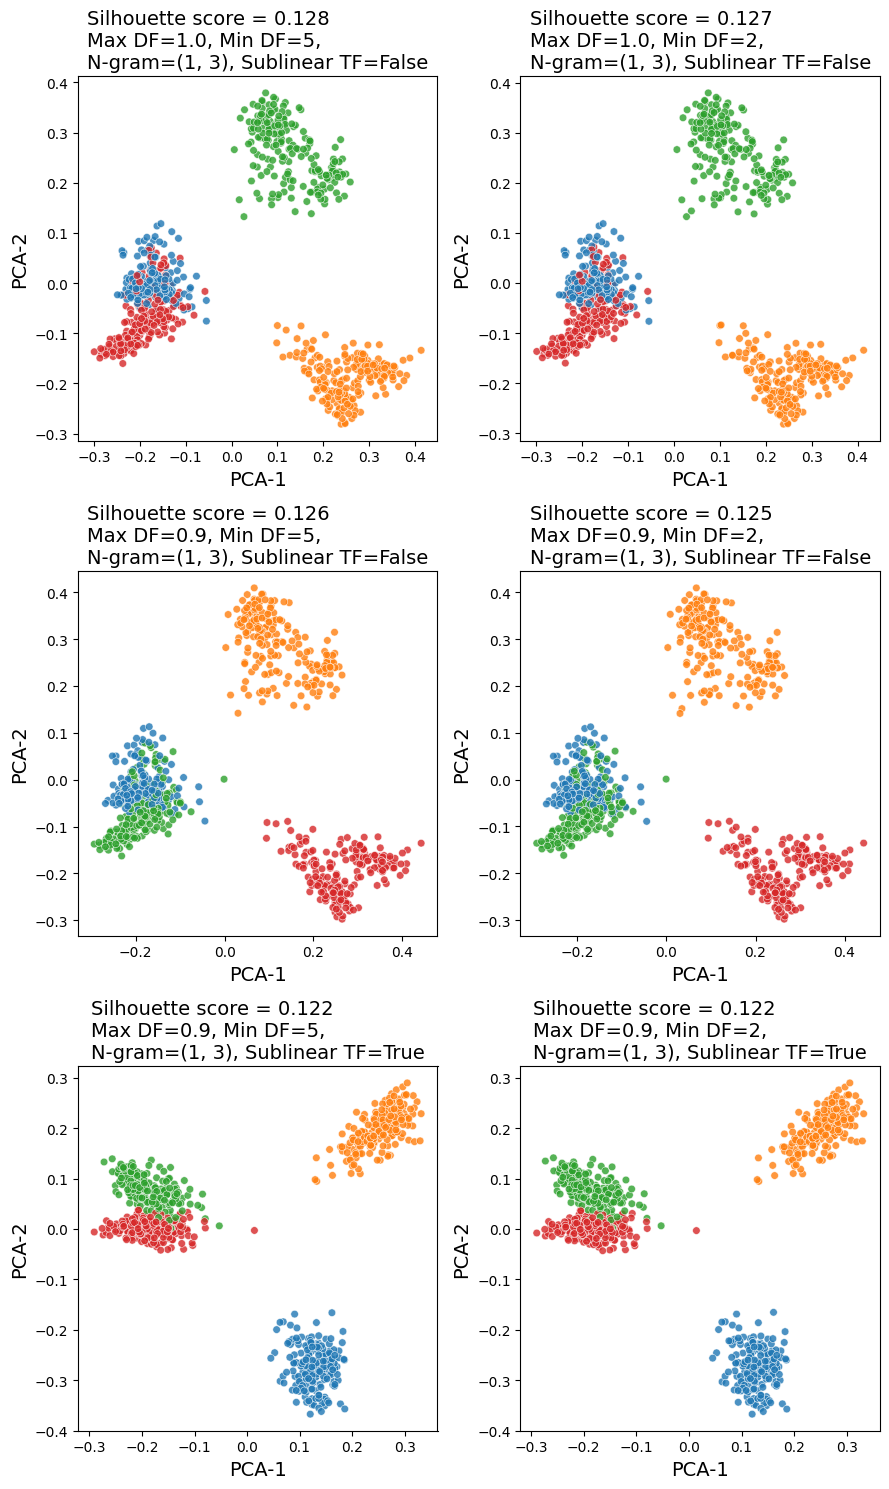

In [378]:
results_sorted = sorted(results, key=lambda x: x["silhouette"], reverse=True)

# Prepare data for all plots
results_list = []
X_tfidf_list = []
labels_list = []

for i, res in enumerate(results_sorted[:TOP_K]):
    params = res["params"]

    vectorizer = TfidfVectorizer(
        **FIXED_PARAMS,
        **params,
    )

    X_tfidf = vectorizer.fit_transform(train_df["text"])

    kmeans = KMeans(
        n_clusters=NUMBER_OF_MODELS,
        n_init=10,
        random_state=SEED,
    )

    labels = kmeans.fit_predict(X_tfidf)

    # Store data for grid plotting
    results_list.append(res)
    X_tfidf_list.append(X_tfidf)
    labels_list.append(labels)

# Plot all in a grid
plot_kmeans_clusters_grid(results_list, X_tfidf_list, labels_list)

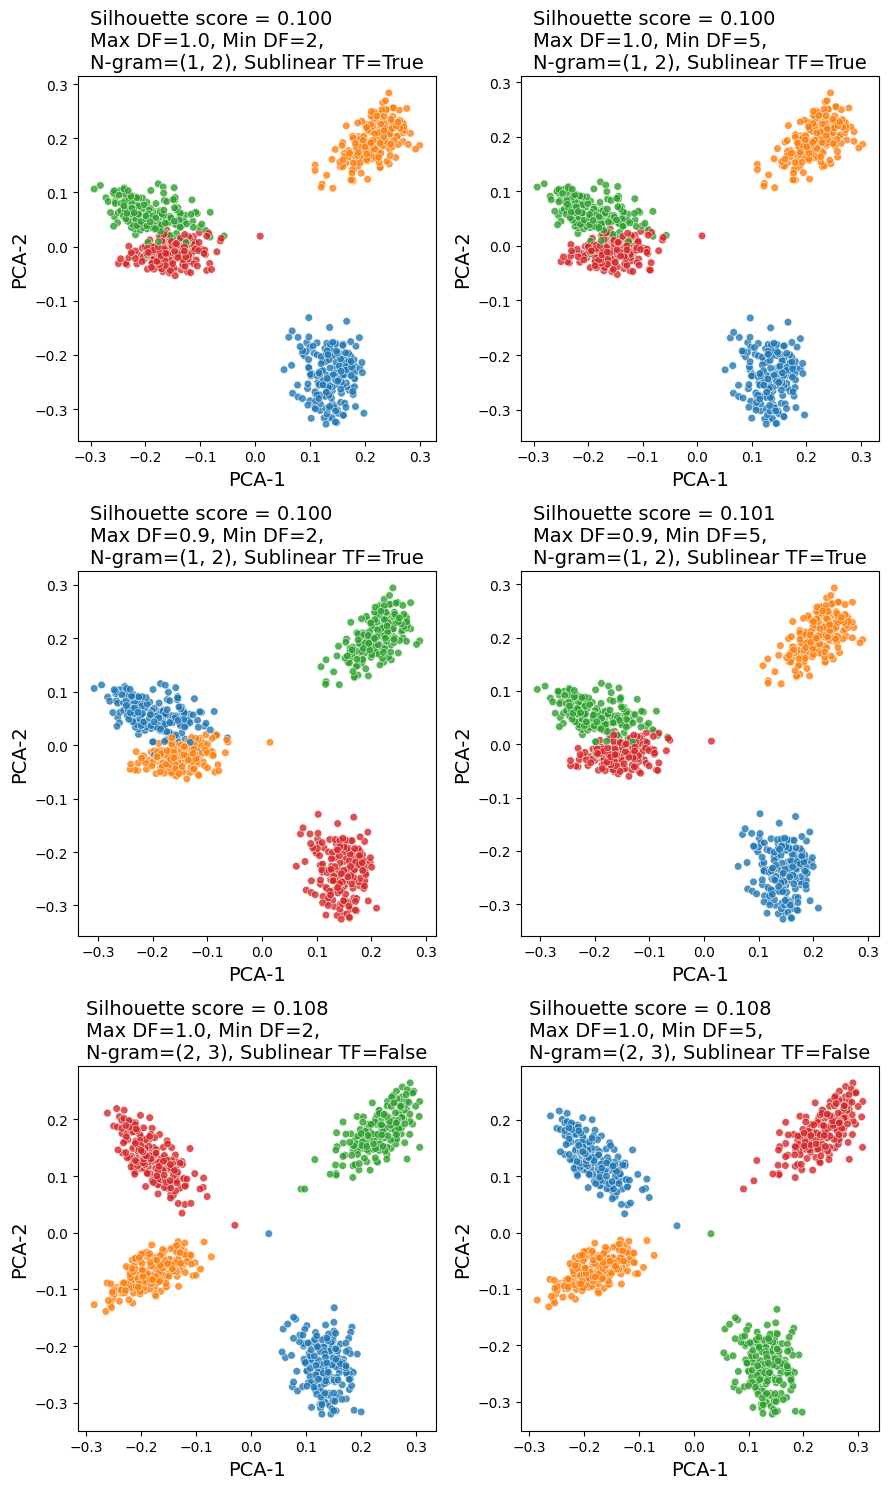

In [379]:
results_sorted = sorted(results, key=lambda x: x["silhouette"], reverse=False)

# Prepare data for all plots
results_list = []
X_tfidf_list = []
labels_list = []

for i, res in enumerate(results_sorted[:TOP_K]):
    params = res["params"]

    vectorizer = TfidfVectorizer(
        **FIXED_PARAMS,
        **params,
    )

    X_tfidf = vectorizer.fit_transform(train_df["text"])

    kmeans = KMeans(
        n_clusters=NUMBER_OF_MODELS,
        n_init=10,
        random_state=SEED,
    )

    labels = kmeans.fit_predict(X_tfidf)

    # Store data for grid plotting
    results_list.append(res)
    X_tfidf_list.append(X_tfidf)
    labels_list.append(labels)

# Plot all in a grid
plot_kmeans_clusters_grid(results_list, X_tfidf_list, labels_list)

## Train an SVM Classifier

In [380]:
import numpy as np
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
import pandas as pd

In [381]:
svm_pipeline = Pipeline(
    [
        ("tfidf", best_vectorizer),
        (
            "svm",
            LinearSVC(
                random_state=SEED,
                multi_class="ovr",
            ),
        ),
    ]
)

In [382]:
svm_pipeline.fit(train_df["text"], train_df["model"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidf', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",<function <la...x7fe0f6bbecf0>
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [383]:
y_pred = svm_pipeline.predict(test_df["text"])

acc = accuracy_score(test_df["model"], y_pred)
cm = confusion_matrix(test_df["model"], y_pred)
report = classification_report(test_df["model"], y_pred, digits=3)

print(f"Test Accuracy: {acc:.3f}\n")
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(report)


Test Accuracy: 1.000

Confusion Matrix:
[[52  0  0  0]
 [ 0 52  0  0]
 [ 0  0 45  0]
 [ 0  0  0 51]]

Classification Report:
                     precision    recall  f1-score   support

    aya-expanse:32b      1.000     1.000     1.000        52
llama3.2-vision:90b      1.000     1.000     1.000        52
        qwen2.5:32b      1.000     1.000     1.000        45
        qwen2.5:72b      1.000     1.000     1.000        51

           accuracy                          1.000       200
          macro avg      1.000     1.000     1.000       200
       weighted avg      1.000     1.000     1.000       200



In [384]:
# Label shuffling check
rng = np.random.default_rng(SEED)
y_shuffled = rng.permutation(train_df["model"].values)

svm_pipeline.fit(train_df["text"], y_shuffled)
y_rand = svm_pipeline.predict(test_df["text"])

print("Shuffled accuracy:", accuracy_score(test_df["model"], y_rand))

Shuffled accuracy: 0.24


In [385]:
for model in dataset['model'].unique():
    avg_length = dataset[dataset['model'] == model]['text'].apply(len).mean()
    print(f"Average text length for {model}: {avg_length:.2f} characters")

Average text length for llama3.2-vision:90b: 5260.45 characters
Average text length for qwen2.5:72b: 3410.75 characters
Average text length for aya-expanse:32b: 7210.66 characters
Average text length for qwen2.5:32b: 2886.58 characters


In [386]:
# Get decision function scores (distance from hyperplane)
decision_scores = svm_pipeline.decision_function(test_df["text"])

# For each test sample, find the margin (confidence)
# In one-vs-rest, we have one score per class
predicted_labels = svm_pipeline.predict(test_df["text"])
true_labels = test_df["model"].values

# Calculate confidence as difference between top 2 scores
confidence_margins = []
for i, scores in enumerate(decision_scores):
    sorted_scores = np.sort(scores)[::-1]
    margin = sorted_scores[0] - sorted_scores[1]  # Gap between 1st and 2nd
    confidence_margins.append(margin)

confidence_margins = np.array(confidence_margins)

print(f"Mean confidence margin: {confidence_margins.mean():.4f}")
print(f"Std confidence margin: {confidence_margins.std():.4f}")
print(f"Min confidence margin: {confidence_margins.min():.4f}")
print(f"Max confidence margin: {confidence_margins.max():.4f}")

Mean confidence margin: 0.2296
Std confidence margin: 0.1845
Min confidence margin: 0.0006
Max confidence margin: 0.7785


In [387]:
# Extract SVM model and feature names
svm_model = svm_pipeline.named_steps['svm']
feature_names = best_vectorizer.get_feature_names_out()

N_FEATURES = 5  # Number of top features to show

# For each model show top distinctive features
for i, model_name in enumerate(svm_model.classes_):
    print(f"\n{'='*80}")
    print(f"MODEL: {model_name}")
    
    # Get coefficients for this class ovr
    coef = svm_model.coef_[i]
    
    # Top N_FEATURES positive features
    top_positive_idx = np.argsort(coef)[-N_FEATURES:][::-1]
    print(f"\nTop {N_FEATURES} features predicting this model:")
    for idx in top_positive_idx:
        print(f"  {feature_names[idx]:30s} : {coef[idx]:8.4f}")
    
    # Top N_FEATURES negative features
    top_negative_idx = np.argsort(coef)[:N_FEATURES]
    print(f"\nTop {N_FEATURES} features predicting NOT this model:")
    for idx in top_negative_idx:
        print(f"  {feature_names[idx]:30s} : {coef[idx]:8.4f}")


MODEL: aya-expanse:32b

Top 5 features predicting this model:
  Alessia                        :   1.1923
  più                            :   0.6923
  con il                         :   0.6373
  nonni                          :   0.6360
  il latte                       :   0.6359

Top 5 features predicting NOT this model:
  Potresti                       :  -0.6836
  capricci                       :  -0.6457
  le                             :  -0.6383
  le sue                         :  -0.6364
  sue                            :  -0.6267

MODEL: llama3.2-vision:90b

Top 5 features predicting this model:
  Ciao                           :   0.8487
  venerdì                        :   0.7520
  nella scelta                   :   0.7482
  nella                          :   0.7412
  scegli per                     :   0.6922

Top 5 features predicting NOT this model:
  Alessia                        :  -0.7350
  Giovanni                       :  -0.6602
  una dieta più                  :  

In [388]:
def check_formatting(text):
    """Extract formatting features from text"""
    return {
        "newline_count": text.count("\n"),
        "quote_count": text.count('"') + text.count("'"),
        "question_count": text.count("?"),
        "exclamation_count": text.count("!"),
        "colon_count": text.count(":"),
        "avg_line_length": (
            np.mean([len(line) for line in text.split("\n")])
            if "\n" in text
            else len(text)
        ),
    }


formatting_features = dataset.groupby("model")["text"].apply(
    lambda texts: pd.DataFrame([check_formatting(t) for t in texts]).mean()
)

print(formatting_features)

model                                 
aya-expanse:32b      newline_count        93.288000
                     quote_count          17.980000
                     question_count       13.664000
                     exclamation_count    12.724000
                     colon_count          20.208000
                     avg_line_length      74.861421
llama3.2-vision:90b  newline_count        60.944000
                     quote_count          12.688000
                     question_count       19.980000
                     exclamation_count    23.144000
                     colon_count           5.136000
                     avg_line_length      94.460092
qwen2.5:32b          newline_count        54.720000
                     quote_count           5.136000
                     question_count       15.888000
                     exclamation_count    10.200000
                     colon_count           2.516000
                     avg_line_length      52.503392
qwen2.5:72b          newl

In [389]:
# Check if formatting alone can separate models
from sklearn.ensemble import RandomForestClassifier

X_train_fmt = np.array(
    [
        [
            text.count("\n"),
            text.count("?"),
            text.count("!"),
            len(text),
            len(text.split()),
        ]
        for text in train_df["text"]
    ]
)

X_test_fmt = np.array(
    [
        [
            text.count("\n"),
            text.count("?"),
            text.count("!"),
            len(text),
            len(text.split()),
        ]
        for text in test_df["text"]
    ]
)

rf = RandomForestClassifier(random_state=SEED, n_estimators=50)
rf.fit(X_train_fmt, train_df["model"])
format_acc = rf.score(X_test_fmt, test_df["model"])

print(f"Accuracy using ONLY formatting features: {format_acc:.4f}")

Accuracy using ONLY formatting features: 0.9050


## Centroid analysis

In [390]:
# Vectorize training data
X_tfidf = best_vectorizer.fit_transform(train_df["text"])

# Fit k-means
kmeans = KMeans(n_clusters=NUMBER_OF_MODELS, n_init=10, random_state=SEED)

kmeans.fit(X_tfidf)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [391]:
feature_names = np.array(best_vectorizer.get_feature_names_out())
feature_names

array(['Abbiamo', 'Abbiamo stabilito', 'Achievable', ...,
       'zucchero nella', 'zucchero nella dieta', 'zuppe'],
      shape=(15000,), dtype=object)

In [392]:
def top_centroid_features(kmeans, feature_names, top_n=10):
    centroids = kmeans.cluster_centers_
    top_features = {}

    for i, centroid in enumerate(centroids):
        top_idx = np.argsort(centroid)[::-1][:top_n]
        top_features[i] = feature_names[top_idx]

    return top_features


def top_centroid_features_with_weights(kmeans, feature_names, top_n=10):
    centroids = kmeans.cluster_centers_
    result = {}

    for i, centroid in enumerate(centroids):
        top_idx = np.argsort(centroid)[::-1][:top_n]
        result[i] = list(zip(feature_names[top_idx], centroid[top_idx]))

    return result

In [393]:
top_features = top_centroid_features(
    kmeans,
    feature_names
)

for cluster_id, terms in top_features.items():
    print(f"\nCluster {cluster_id} top terms:")
    print(", ".join(terms))

print("\n\t" + 100 * "=")

top_features_with_weights = top_centroid_features_with_weights(
    kmeans,
    feature_names
)


for cluster_id, terms_weights in top_features_with_weights.items():
    print(f"\nCluster {cluster_id} top terms with weights:")
    for term, weight in terms_weights:
        print(f"{term}: {weight:.4f}")



Cluster 0 top terms:
di, per, Luca, un, il, con, Marco, in, acqua, Sono

Cluster 1 top terms:
di, per, Leo, un, Marco, con, il, la, Sara, in

Cluster 2 top terms:
di, per, un, Alessandro, Sofia, Leo, il, Luca, che, in

Cluster 3 top terms:
di, per, Giovanna, il, Marco, acqua, in, un, con, questo


Cluster 0 top terms with weights:
di: 0.1649
per: 0.1164
Luca: 0.1118
un: 0.0830
il: 0.0762
con: 0.0634
Marco: 0.0598
in: 0.0594
acqua: 0.0553
Sono: 0.0445

Cluster 1 top terms with weights:
di: 0.2061
per: 0.1529
Leo: 0.1082
un: 0.0940
Marco: 0.0924
con: 0.0888
il: 0.0793
la: 0.0789
Sara: 0.0677
in: 0.0634

Cluster 2 top terms with weights:
di: 0.1919
per: 0.1333
un: 0.0954
Alessandro: 0.0941
Sofia: 0.0933
Leo: 0.0890
il: 0.0729
Luca: 0.0686
che: 0.0619
in: 0.0588

Cluster 3 top terms with weights:
di: 0.1637
per: 0.1109
Giovanna: 0.0973
il: 0.0741
Marco: 0.0610
acqua: 0.0603
in: 0.0544
un: 0.0510
con: 0.0492
questo: 0.0486


In [394]:
cluster_assignments = kmeans.labels_

df_clusters = pd.DataFrame(
    {"cluster": cluster_assignments, "label": train_df["model"].values}
)

majority_label = df_clusters.groupby("cluster")["label"].agg(
    lambda x: x.value_counts().idxmax()
)

majority_purity = df_clusters.groupby("cluster")["label"].agg(
    lambda x: x.value_counts().max() / len(x)
)

cluster_summary = pd.DataFrame({"model": majority_label, "purity": majority_purity})

cluster_summary

,model,purity
cluster,,
0,qwen2.5:72b,1.000000
1,aya-expanse:32b,1.000000
2,llama3.2-vision:90b,1.000000
3,qwen2.5:32b,0.995146


In [395]:
# Unpure clusters analysis
unpure_clusters = cluster_summary[cluster_summary["purity"] < 1.0]

misclassified_samples = []
for cluster_id in unpure_clusters.index:
    cluster_data = df_clusters[df_clusters["cluster"] == cluster_id]
    majority_model = cluster_summary.loc[cluster_id, "model"]
    misclassified = cluster_data[cluster_data["label"] != majority_model]
    misclassified_samples.append(misclassified)

misclassified_samples

[     cluster            label
 132        3  aya-expanse:32b]

## ARI analysis

In [396]:
from sklearn.metrics import adjusted_rand_score

In [397]:
true_labels = train_df["model"].values

ari = adjusted_rand_score(true_labels, cluster_labels)

silhouette = silhouette_score(X_tfidf, cluster_labels, metric="cosine")

# Random clustering baseline

rng = np.random.default_rng(SEED)
random_labels = rng.integers(0, NUMBER_OF_MODELS, size=len(true_labels))

ari_random = adjusted_rand_score(true_labels, random_labels)
silhouette_random = silhouette_score(X_tfidf, random_labels, metric="cosine")

print(f"Silhouette Score: {silhouette:.4f}")
print(f"ARI: {ari:.4f}")
print(f"ARI baseline: {ari_random:.4f}")
print(f"Silhouette baseline: {silhouette_random:.4f}")
print(f"Improvement over random: {(ari - ari_random):.4f}")

Silhouette Score: 0.1278
ARI: 0.9967
ARI baseline: 0.0006
Silhouette baseline: -0.0045
Improvement over random: 0.9960
